# Parte 2: DQN

Agora o agente aprende. Usamos o `DQN` do **stable-baselines3** (SB3), o mesmo caminho do notebook `1_deep_qlearning` da disciplina. Por dentro, é o algoritmo da aula 4:

- uma rede $\hat Q(s,a;w)$ recebe os **11 valores do estado** e devolve **36 valores Q**, um por ação;
- política **ε-gulosa**: ε começa em 1 (tudo aleatório) e cai até quase 0;
- **repetição de experiência**: as tuplas $(s,a,r,s')$ vão para um buffer $\mathcal{D}$ e o treino usa minibatches sorteados dele, o que quebra a correlação entre horas seguidas;
- **rede-alvo** $w^-$, copiada de $w$ a cada $C$ passos, para o alvo não andar junto com a rede:

$$y = r \text{ (se as duas culturas morreram)}, \qquad y = r + \gamma \max_{a'} \hat Q(s',a';w^-) \text{ (caso contrário)}.$$

Dois detalhes do SB3 que vale saber:

- **Truncamento não é término.** Aos 30 dias o episódio é *truncado*: a estufa não acabou, só paramos de olhar. Nesse passo o SB3 continua usando o alvo com $\max Q$. Só a morte das duas culturas é terminal ($y = r$).
- **Perda de Huber** no lugar do erro quadrático da aula: igual ao quadrado para erros pequenos e linear para erros grandes. Isso evita que os −100 das mortes gerem gradientes enormes.

Roteiro: (5) Drive e hiperparâmetros, (6) função de treino, (7) treino longo, (8) curva de aprendizado, (9) comparação com as linhas de base, (10) o episódio de seca.

## Preparação

O código do simulador fica no arquivo `estufa.py`, na raiz do repositório, para ser usado pelos três notebooks. A célula abaixo clona o repositório (se ainda não estiver clonado), põe a raiz dele no `sys.path` e instala as bibliotecas.


In [ ]:
import os, sys

if os.path.exists("estufa.py"):                  # já está na raiz do repositório
    RAIZ = os.getcwd()
elif os.path.exists("../estufa.py"):             # rodando de dentro de notebooks/
    RAIZ = os.path.abspath("..")
else:                                            # Colab: clona o repositório
    if not os.path.exists("agent-dedoverde"):
        !git clone -q https://github.com/gabrielhca/agent-dedoverde.git
    RAIZ = os.path.abspath("agent-dedoverde")
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)
print("raiz do repositório:", RAIZ)

!pip install -q gymnasium stable-baselines3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from estufa import (CULTURAS, CONFIG, gerar_clima, previsao, EstufaEnv,
                    politica_aleatoria, politica_termostato, rodar, resumo,
                    plot_clima, plot_episodio)


As linhas de base (aleatória e termostato) são recalculadas aqui, nas mesmas 100 sementes (0–99) do notebook `01_modelagem`, porque a curva de aprendizado e a comparação usam `res_aleat` e `res_termo`.


In [8]:
env = EstufaEnv()
res_aleat, _ = rodar(env, politica_aleatoria, n_episodios=100)
res_termo, _ = rodar(env, politica_termostato, n_episodios=100)
resumo("aleatória", res_aleat, env)
resumo("termostato", res_termo, env)

aleatória    retorno   -203.0 ±    1.1 | água    224 L | milho sobrevive   0.0% | feijão-caupi sobrevive   0.0%
termostato   retorno    424.7 ±  201.5 | água   2704 L | milho sobrevive  68.0% | feijão-caupi sobrevive  75.0%


## 5. Google Drive e hiperparâmetros

O modelo treinado, o registro do treino e a curva vão para uma pasta no Drive (`MyDrive/dedoverde`). Se o Colab cair ou você abrir o notebook outro dia, o treino longo **carrega o modelo salvo em vez de treinar de novo**. Fora do Colab (Kaggle ou máquina local), a pasta fica ao lado do notebook.

In [10]:
import os, json, time
import pandas as pd
import torch
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA = "/content/drive/MyDrive/dedoverde"
except ImportError:                      # Kaggle ou máquina local
    PASTA = "dedoverde_saidas"
os.makedirs(PASTA, exist_ok=True)
print("salvando em:", PASTA)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mounted at /content/drive
salvando em: /content/drive/MyDrive/dedoverde


Hiperparâmetros, partindo do `dqn.yml` da disciplina (feito para Space Invaders) e reduzidos para o nosso problema:

| SB3 | Na aula 4 | `dqn.yml` (Atari) | Aqui | Por quê |
|---|---|---|---|---|
| `buffer_size` | tamanho de $\mathcal{D}$ | 1e5 | **5e4** | ≈ 70 episódios completos; problema muito menor que Atari |
| `learning_starts` | encher $\mathcal{D}$ antes de aprender | 1e5 | **1e3** | com 11 números de entrada, mil transições já bastam para começar |
| `batch_size` | minibatch | 32 | 32 | igual |
| `learning_rate` | passo do gradiente | 1e-4 | 1e-4 | igual |
| `target_update_interval` | $C$ | 1000 | 1000 | igual (≈ 1,4 episódio completo) |
| `train_freq` | passos entre atualizações | 4 | 4 | igual |
| `exploration_fraction` | quanto do treino ε leva para cair | 0,1 | **0,06** (60 mil passos) | com ε alto as plantas morrem em ~1 dia; ε precisa cair cedo para o agente ver episódios longos |
| `exploration_final_eps` | ε final | 0,01 | 0,01 | igual |
| `gamma` | γ | 0,99 | 0,99 | decisão do projeto (horizonte ~4 dias) |
| rede | arquitetura | CNN sobre pixels | **MLP 64 × 64** | a entrada são 11 números, não imagens |
| passos totais | | 1e7 | **1e6** | ≈ 1.400 episódios de 30 dias, 250 mil atualizações da rede; ~22 min em CPU |

**Climas de treino e de teste.** O agente treina em climas sorteados a partir de `SEMENTE` (4242) e é comparado nas sementes 0–99, as mesmas das linhas de base da parte 1. A semente do treino fica fora desse intervalo de propósito, para o agente não treinar nos climas do teste. O modelo reportado é o do **fim do treino**: não escolhemos nenhum ponto olhando para o teste.

Usamos CPU de propósito: numa rede deste tamanho, a GPU não ajuda (o tempo vai na simulação, não na rede).

In [11]:
PASSOS_TOTAIS = 1_000_000
PASSOS_EPS = 60_000               # passos até ε chegar ao valor final
SEMENTE = 4242                    # fora de 0–99 (teste)

HIPER = dict(
    learning_rate=1e-4,
    buffer_size=50_000,           # D
    learning_starts=1_000,        # transições aleatórias antes do 1º gradiente
    batch_size=32,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=1_000, # C
    exploration_fraction=PASSOS_EPS / PASSOS_TOTAIS,   # ε cai de 1 até 0,01 em 60 mil passos
    exploration_initial_eps=1.0,
    exploration_final_eps=0.01,
    policy_kwargs=dict(net_arch=[64, 64]),
)

# Cada treino fica numa subpasta própria do Drive, nomeada pelos passos e pela semente.
PASTA_RODADA = os.path.join(PASTA, f"{PASSOS_TOTAIS // 1000}k_s{SEMENTE}")
print("rodada atual:", PASTA_RODADA)

rodada atual: /content/drive/MyDrive/dedoverde/1000k_s4242


## 6. Função de treino

O que `treinar` faz:

- envolve o ambiente num `Monitor`, que grava retorno e duração de cada episódio num CSV (é daí que sai a **curva de aprendizado**);
- `Progresso`: imprime de tempos em tempos o ε atual e a média dos últimos 20 episódios de treino;
- no fim, salva o modelo (`dqn_final.zip`) e os hiperparâmetros (`hiper.json`).

`politica_dqn` adapta o modelo ao formato `politica(env, obs, info)` que `rodar()` já usa na parte 1, com ε = 0 (sempre a ação de maior Q). Assim o DQN é avaliado pela mesma função e nos mesmos climas das linhas de base.

In [12]:
class Progresso(BaseCallback):
    # Imprime ε e a média dos últimos episódios de treino a cada `a_cada` passos.
    def __init__(self, a_cada):
        super().__init__()
        self.a_cada = a_cada

    def _on_training_start(self):
        self.t0 = time.time()

    def _on_step(self):
        if self.num_timesteps % self.a_cada == 0:
            eps = list(self.model.ep_info_buffer)[-20:]
            if eps:
                r = np.mean([e["r"] for e in eps])
                dias = np.mean([e["l"] for e in eps]) / 24
                print(f"{self.num_timesteps:>9,d} passos | ε = {self.model.exploration_rate:.2f} | "
                      f"treino, últimos {len(eps)} ep.: retorno {r:7.1f}, duração {dias:5.1f} dias | "
                      f"{(time.time() - self.t0) / 60:5.1f} min")
        return True


def treinar(total_passos, pasta, hiper=HIPER, a_cada=25_000, seed=SEMENTE):
    os.makedirs(pasta, exist_ok=True)
    env_treino = Monitor(EstufaEnv(), filename=os.path.join(pasta, "treino"))   # -> treino.monitor.csv
    modelo = DQN("MlpPolicy", env_treino, seed=seed, device="cpu", verbose=0, **hiper)
    t0 = time.time()
    modelo.learn(total_timesteps=total_passos, callback=Progresso(a_cada))
    dt = time.time() - t0
    modelo.save(os.path.join(pasta, "dqn_final"))
    with open(os.path.join(pasta, "hiper.json"), "w") as f:
        json.dump(dict(hiper, total_passos=total_passos, seed=seed, minutos=dt / 60), f, indent=2)
    return modelo, dt


def politica_dqn(modelo):
    # deterministic=True: ε = 0, sempre a ação de maior Q.
    return lambda env, obs, info: int(modelo.predict(obs, deterministic=True)[0])


def plot_curva(pasta, titulo, refs=None, janela=20, salvar=True):
    # Curva de aprendizado: retorno e duração de cada episódio de treino (média móvel).
    df = pd.read_csv(os.path.join(pasta, "treino.monitor.csv"), skiprows=1)
    passos = df["l"].cumsum()
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    ax[0].plot(passos, df["r"], color="tab:blue", alpha=0.15, lw=0.6)
    ax[0].plot(passos, df["r"].rolling(janela, min_periods=1).mean(), color="tab:blue",
               lw=1.6, label=f"treino, com exploração (média móvel de {janela} ep.)")
    for (nome, valor), cor in zip((refs or {}).items(), ["tab:red", "tab:gray"]):
        ax[0].axhline(valor, color=cor, ls="--", lw=1, label=f"{nome} ({valor:.0f})")
    ax[0].set_ylabel("retorno do episódio"); ax[0].legend(loc="lower right", fontsize=8)
    ax[0].set_title(titulo)
    ax[1].plot(passos, df["l"] / 24, color="tab:green", alpha=0.15, lw=0.6)
    ax[1].plot(passos, (df["l"] / 24).rolling(janela, min_periods=1).mean(), color="tab:green", lw=1.6)
    ax[1].axhline(30, color="k", ls=":", lw=1)
    ax[1].set_ylabel("duração (dias)\n30 = alguma cultura viva no fim"); ax[1].set_xlabel("passos de treino")
    plt.tight_layout()
    if salvar:
        fig.savefig(os.path.join(pasta, "curva_aprendizado.png"), dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{len(df)} episódios de treino")

## 7. Treino longo (1 milhão de passos, ~22 min)

Se já existe `dqn_final.zip` na pasta deste treino, carrega em vez de treinar. Para treinar de novo, troque `FORCAR_TREINO` para `True` (sobrescreve o modelo e o registro desta pasta). A saída guardada abaixo é a do treino de 16/11, feito com `FORCAR_TREINO = True`; com `False`, a célula só carrega o modelo salvo.

Deixe a aba do Colab aberta durante o treino: se a sessão cair no meio, ele recomeça do zero.

No registro impresso, repare no ε e na duração dos episódios: nos primeiros 60 mil passos eles duram horas (ε alto, o agente encharca os canteiros) e depois sobem para perto de 30 dias.

In [13]:
FORCAR_TREINO = False
ARQ_FINAL = os.path.join(PASTA_RODADA, "dqn_final.zip")

if FORCAR_TREINO or not os.path.exists(ARQ_FINAL):
    modelo_final, dt = treinar(PASSOS_TOTAIS, PASTA_RODADA)
    print(f"\ntreino: {dt / 60:.1f} min")
else:
    modelo_final = DQN.load(ARQ_FINAL, device="cpu")
    print("modelo carregado do Drive:", ARQ_FINAL)
    with open(os.path.join(PASTA_RODADA, "hiper.json")) as f:
        print(json.load(f))

print("\nrede:", modelo_final.q_net)

   25,000 passos | ε = 0.59 | treino, últimos 20 ep.: retorno  -200.1, duração   1.0 dias |   0.5 min


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


   50,000 passos | ε = 0.18 | treino, últimos 20 ep.: retorno  -160.8, duração  10.0 dias |   1.0 min
   75,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   -69.4, duração  18.9 dias |   1.5 min
  100,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno  -122.0, duração  12.2 dias |   2.1 min
  125,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno    11.6, duração  21.6 dias |   2.6 min
  150,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   130.2, duração  25.4 dias |   3.1 min
  175,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   213.9, duração  27.1 dias |   3.7 min
  200,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   212.2, duração  25.6 dias |   4.2 min
  225,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   346.5, duração  29.3 dias |   4.7 min
  250,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   329.4, duração  28.0 dias |   5.3 min
  275,000 passos | ε = 0.01 | treino, últimos 20 ep.: retorno   291.5, duração  26

## 8. Curva de aprendizado

Em cima, o **retorno** de cada episódio de treino (claro) e a média móvel (escuro). São climas sorteados e o agente ainda explora (ε final = 0,01), então a curva não é uma medida do agente "jogando de verdade": para isso, a seção 9. As linhas tracejadas são a média do termostato e da política aleatória nos 100 climas de teste, só como referência de escala.

Embaixo, **quanto tempo cada episódio de treino durou**: 30 dias quer dizer que pelo menos uma cultura chegou viva ao fim.

A figura também é salva no Drive (`curva_aprendizado.png`, na pasta da rodada).

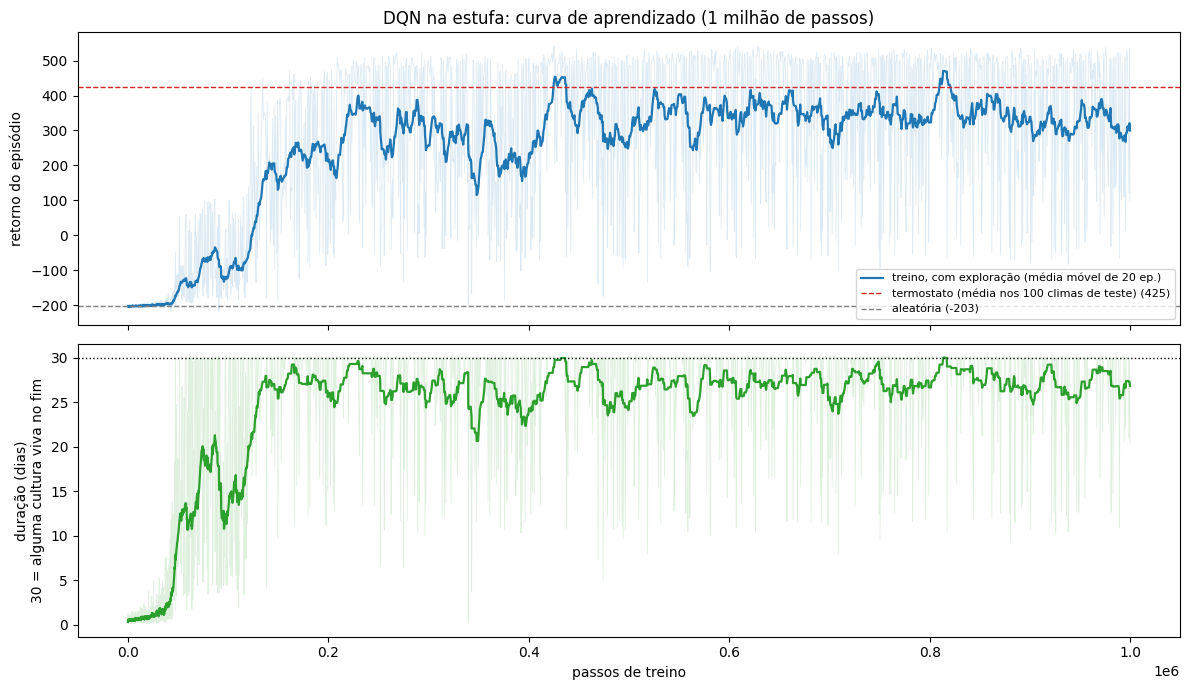

3681 episódios de treino


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
refs = {"termostato (média nos 100 climas de teste)": np.mean([x["retorno"] for x in res_termo]),
        "aleatória": np.mean([x["retorno"] for x in res_aleat])}
plot_curva(PASTA_RODADA, "DQN na estufa: curva de aprendizado (1 milhão de passos)", refs=refs)

## 9. Comparação com as linhas de base (teste)

As mesmas 100 sementes (0–99) da parte 1, para todas as políticas: cada uma enfrenta exatamente os mesmos climas. O DQN joga sem exploração (ε = 0) e é o modelo do fim do treino. Estes climas não foram usados no treino.

O "±" é o desvio padrão do retorno entre os 100 climas, não uma margem de erro: o retorno varia muito de um clima para outro (o termostato faz 425 ± 200), então diferenças pequenas entre médias não indicam, sozinhas, qual política é melhor.

Os resultados por episódio vão para `comparacao.csv` na pasta da rodada.

In [15]:
env = EstufaEnv()
res_dqn, _ = rodar(env, politica_dqn(modelo_final), n_episodios=100)

politicas = [("aleatória", res_aleat), ("termostato", res_termo), ("DQN", res_dqn)]
for nome, r in politicas:
    resumo(nome, r, env)

tabela = pd.concat([pd.DataFrame(r).assign(politica=nome, semente=range(len(r))) for nome, r in politicas])
tabela.to_csv(os.path.join(PASTA_RODADA, "comparacao.csv"), index=False)

aleatória    retorno   -203.0 ±    1.1 | água    224 L | milho sobrevive   0.0% | feijão-caupi sobrevive   0.0%
termostato   retorno    424.7 ±  201.5 | água   2704 L | milho sobrevive  68.0% | feijão-caupi sobrevive  75.0%
DQN          retorno    329.6 ±  207.3 | água   2652 L | milho sobrevive  46.0% | feijão-caupi sobrevive  68.0%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Leitura da comparação (100 climas de teste).**

- O DQN aprendeu: saiu do nível da política aleatória (−203) e chegou a 330 de retorno médio.
- Não superou o termostato (425). Fica abaixo em retorno e, nas culturas, o milho sobrevive menos (46% contra 68%) e o feijão também (68% contra 75%).
- O DQN gasta um pouco menos de água que o termostato (2652 L contra 2704 L), mas perde mais culturas, então isso não mostra que ele economiza melhor.
- O retorno varia muito de um clima para outro (desvio de uns 200, igual para as duas políticas), por isso o foco é a média e a sobrevivência, não diferenças pequenas.
- Fizemos um único treino (uma semente). Não sabemos quanto o resultado varia de um treino para outro.

## 10. O mesmo episódio de seca: termostato × DQN

No **episódio 1** chove perto do dia 2,7 e só volta a chover no dia 23,6: são **21 dias de estiagem** com um tanque de 1500 L. O termostato segue regando os dois canteiros como se nada fosse, esvazia o tanque e perde as duas culturas (dias ~18,5 e ~19,6), antes de a chuva voltar. O clima é idêntico para as duas políticas (mesma semente), então qualquer diferença vem só das decisões.

Os gráficos têm o mesmo formato para as duas políticas: temperatura com a faixa comum, umidade de cada canteiro com sua faixa ideal, tanque com chuva e previsão, e as ações embaixo. Vale olhar se o DQN rega diferente do termostato quando o tanque baixa, e quando cada cultura morre.

Termostato: retorno 111.1 | água 1750 L | tanque no fim 0 L | mortes: milho no dia 18.5, feijão-caupi no dia 19.6


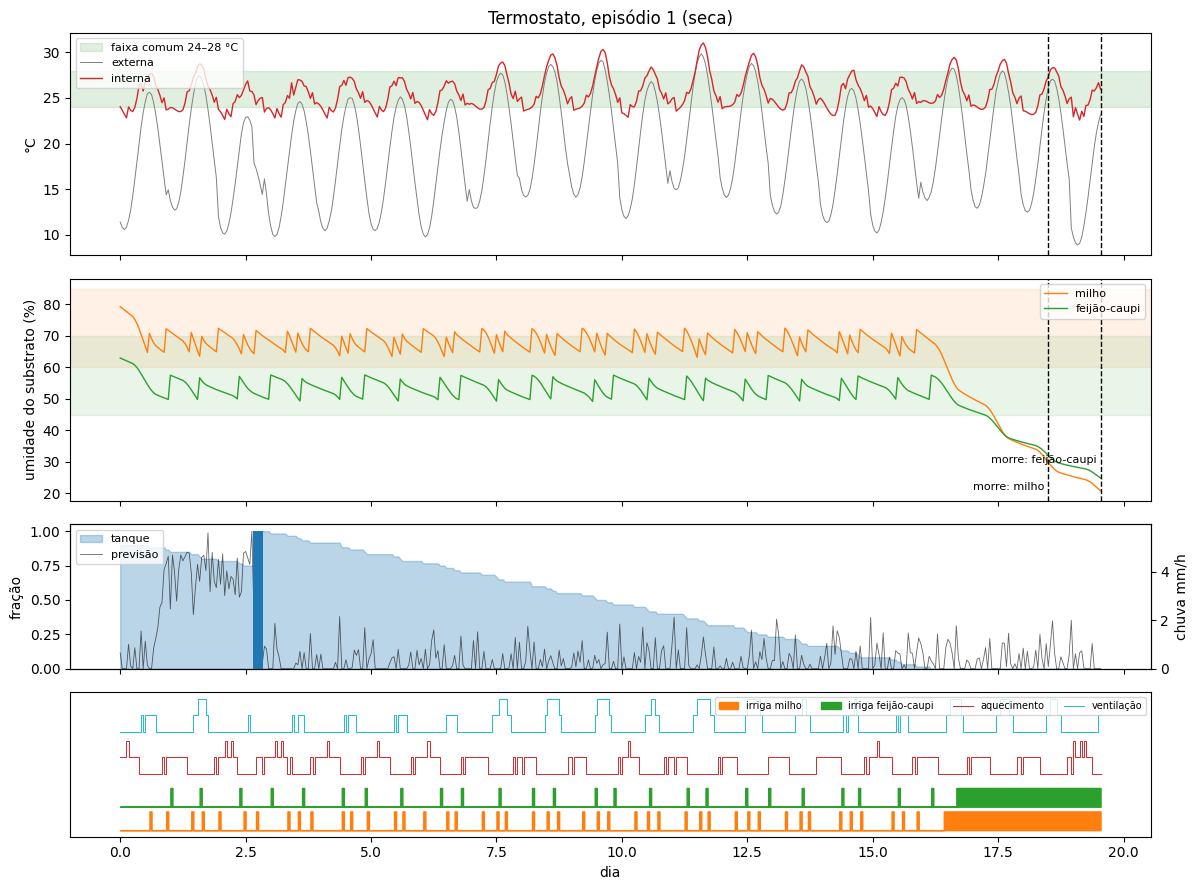

DQN: retorno 83.8 | água 1800 L | tanque no fim 0 L | mortes: milho no dia 17.4, feijão-caupi no dia 18.7


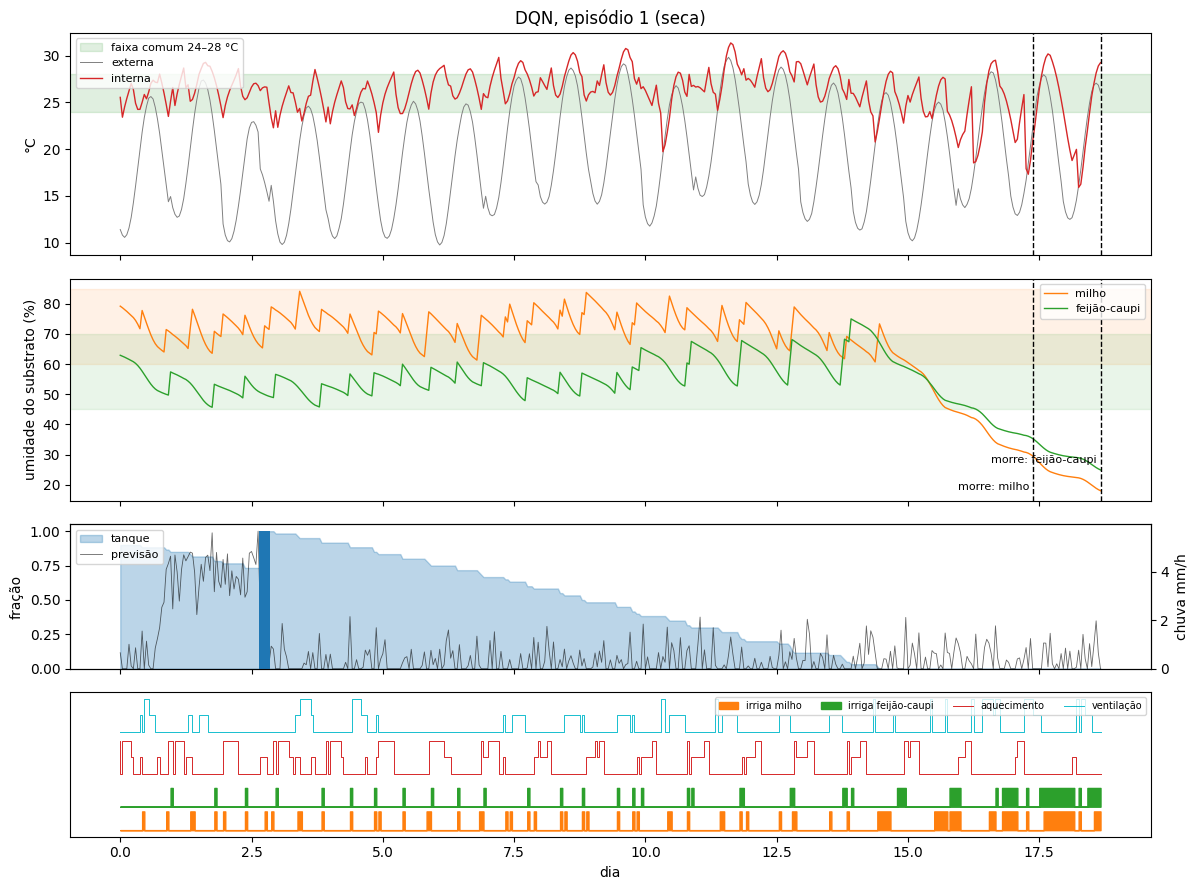

In [16]:
SEED_SECA = 1


def mortes(traj):
    return [f"{nome} no dia {s['t'] / 24:.1f}" for s in traj for nome in s["mortes"]] or ["nenhuma"]


for nome, pol in [("Termostato", politica_termostato), ("DQN", politica_dqn(modelo_final))]:
    res, traj = rodar(env, pol, n_episodios=1, seed=SEED_SECA, guardar=True)
    print(f"{nome}: retorno {res[0]['retorno']:.1f} | água {res[0]['agua']:.0f} L | "
          f"tanque no fim {traj[-1]['tanque']:.0f} L | mortes: {', '.join(mortes(traj))}")
    plot_episodio(traj, env, f"{nome}, episódio {SEED_SECA} (seca)")

**Leitura do episódio de seca.**

- O termostato regou os dois canteiros até o tanque esvaziar e perdeu as duas culturas (dias 18,5 e 19,6), com retorno 111.
- O DQN fez o mesmo: regou os dois canteiros até esvaziar o tanque, por volta do dia 14,5, e não abandonou nenhum. Perdeu o milho no dia 17,4 e o feijão no dia 18,7, um pouco antes do termostato, com retorno 84. A chuva só volta no dia 23,6.
- Ou seja, nesta seca o DQN não aprendeu a economizar água para salvar pelo menos uma cultura, mesmo vendo o nível do tanque e a previsão de chuva. Não investigamos a causa.